In [1]:
# https://github.com/prophesee-ai/openeb/blob/5.2.0/sdk/modules/stream/python/samples/metavision_sdk_get_started/metavision_sdk_get_started_v2.py
import evcam
import numpy as np
from PIL import Image
from metavision_sdk_core import BaseFrameGenerationAlgorithm
from metavision_sdk_stream import Camera, CameraStreamSlicer, Slice, SliceCondition


In [2]:
with evcam.quiet_stderr(): 
    camera: Camera = Camera.from_first_available()


slicer: CameraStreamSlicer = CameraStreamSlicer(camera.move(), slice_condition=SliceCondition.make_n_us(10_000))
width: int = slicer.camera().width()
height: int = slicer.camera().height()
print(f"{width} x {height}")


1280 x 720


In [6]:
global_counter: int = 0  # This will track how many events we processed
global_max_t: int = 0  # This will track the highest timestamp we processed

slice: Slice
for i, slice in enumerate(slicer):
    print("----- New event slice! -----")
    if slice.events.size == 0:
        print("The current event slice is empty.")
    else:
        min_t = slice.events['t'][0]   # Get the timestamp of the first event of this slice
        max_t = slice.events['t'][-1]  # Get the timestamp of the last event of this callback
        global_max_t = max_t  # Events are ordered by timestamp, so the current last event has the highest timestamp

        counter = slice.events.size  # Local counter
        global_counter += counter  # Increase global counter

        print(f"There were {counter} events in this event slice.")
        print(f"There were {global_counter} total events up to now.")
        print(f"The current event slice included events from {min_t} to {max_t} microseconds.")
        print("----- End of the event slice! -----")
    if i == 9:
        break


----- New event slice! -----
There were 23332 events in this event slice.
There were 23332 total events up to now.
The current event slice included events from 110000 to 119999 microseconds.
----- End of the event slice! -----
----- New event slice! -----
There were 24862 events in this event slice.
There were 48194 total events up to now.
The current event slice included events from 120000 to 129999 microseconds.
----- End of the event slice! -----
----- New event slice! -----
There were 20847 events in this event slice.
There were 69041 total events up to now.
The current event slice included events from 130000 to 139999 microseconds.
----- End of the event slice! -----
----- New event slice! -----
There were 17881 events in this event slice.
There were 86922 total events up to now.
The current event slice included events from 140000 to 149999 microseconds.
----- End of the event slice! -----
----- New event slice! -----
There were 17591 events in this event slice.
There were 104513 

In [7]:
duration_seconds = global_max_t / 1.0e6
print(f"There were {global_counter} events in total.")
print(f"The total duration was {duration_seconds:.2f} seconds.")
if duration_seconds >= 1:  # No need to print this statistics if the total duration was too short
    print(f"There were {global_counter / duration_seconds :.2f} events per second on average.")


There were 302172 events in total.
The total duration was 0.21 seconds.


In [140]:
len(slicer)

TypeError: object of type 'metavision_sdk_stream.CameraStreamSlicer' has no len()

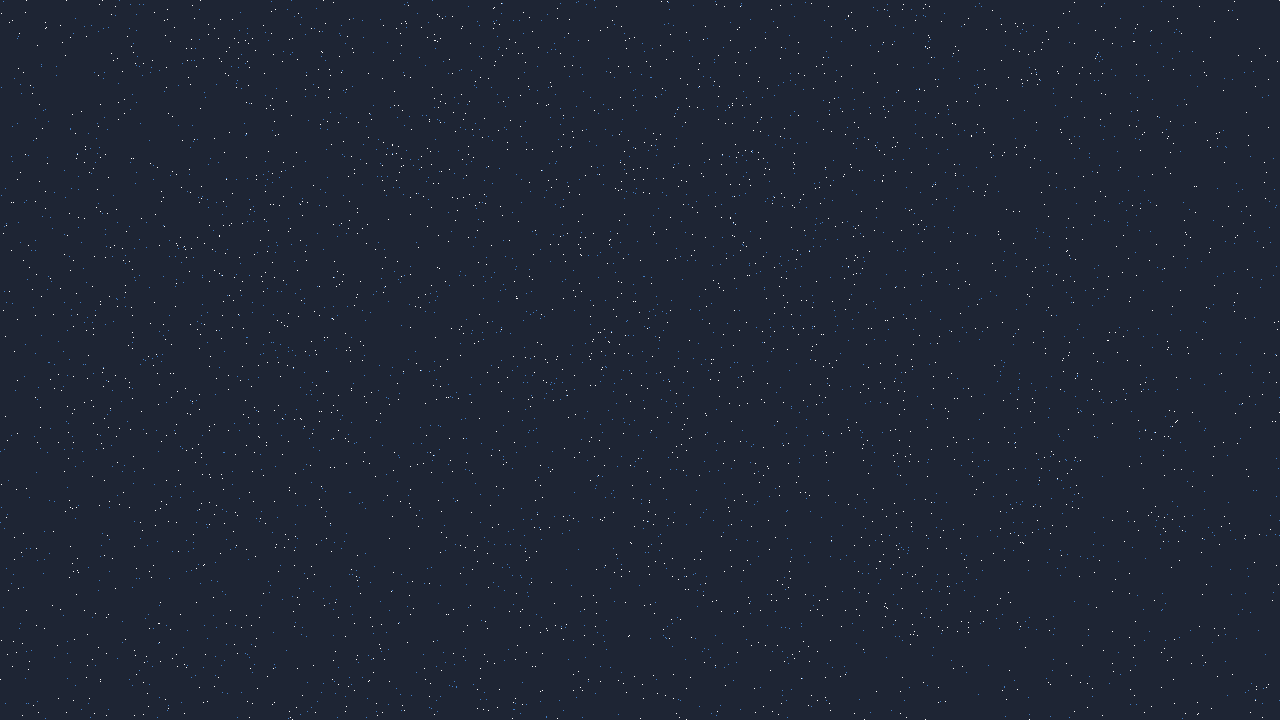

In [163]:
frame: np.ndarray = np.zeros((height, width, 3), np.uint8)

slice: Slice = next(iter(slicer))
BaseFrameGenerationAlgorithm.generate_frame(slice.events, frame)
Image.fromarray(frame[..., ::-1])


In [ ]:
del slicer, slice
